# Matching Markets: When Prices Can't Do the Job

> Computational Analysis of Social Complexity
>
> Fall 2026, Spencer Lyon

**Prerequisites**

- [Platforms and Matchmakers](../week10/L10.01_platform_economics.ipynb), [Ignition](../week10/L10.02_ignition_and_tipping.ipynb), and [Platform Pricing](../week11/L11.01_platform_pricing.ipynb)
- Auctions (week 9)
- {term}`Graphs <graph>` (week 3)
- DataFrames and CSV (weeks 1–2)

**Outcomes**

- Define stability and {term}`blocking pairs <blocking pair>` in two-sided matching
- Implement Gale–Shapley {term}`deferred acceptance` and a stability checker in {term}`Julia`
- Explain {term}`proposer-optimality` and its market-design consequences
- Compute {term}`market-clearing prices` with an ascending-price auction and explain why the resulting match maximizes total value
- Simulate how hidden quality unravels a market and how reputation can sustain it
- Analyze a real marketplace dataset from a two-sided perspective

**References**

- [Easley and Kleinberg, Chapter 10: Matching Markets (required)](https://www.cs.cornell.edu/home/kleinber/networks-book/networks-book.pdf)
- [The Prize in Economic Sciences 2012: Stable Allocations and the Practice of Market Design (required)](https://www.nobelprize.org/uploads/2018/06/popular-economicsciences2012.pdf)
- Gale and Shapley (1962), "College Admissions and the Stability of Marriage"
- Roth, *Who Gets What—and Why* (optional)
- [Easley and Kleinberg, Chapter 22, §§22.6 and 22.9: Lemons and Reputation Systems (required)](https://www.cs.cornell.edu/home/kleinber/networks-book/networks-book.pdf)
- *Matchmakers* (Evans and Schmalensee, 2016), chapters 4, 8, and 9 (optional reading)

## You Need a Kidney

- Roughly **100,000 people** are on the U.S. organ-transplant waitlist
- Paying someone for a kidney is a felony in the United States, and organ sales are prohibited nearly everywhere
- Yet thousands of transplants happen each year between people who began as strangers
  - An incompatible donor–patient pair can swap with another pair
  - An algorithm searches for compatible cycles and chains
- Algorithms from the same matching family assign every U.S. medical resident to a hospital and many New York City students to public schools
- Some markets are {term}`repugnant <repugnant market>` to clear with prices—or simply too complex—so we design the **match**
- This marriage of theory and practice earned Alvin Roth and Lloyd Shapley the 2012 Nobel Prize in Economic Sciences

### When a Price Is Not the Answer

- Last time we separated a {term}`platform`'s **{term}`price structure`** from its **{term}`price level`**
- But what if the right price is illegal, unacceptable, or not enough to identify who should meet whom?
- A hospital cares which doctor it hires; a doctor cares which hospital hires them
- These are {term}`two-sided markets <two-sided market>`, but the central object is a pair—not a transaction price
- Today we replace willingness-to-pay with **preference rankings**

## Build 1: The Stable Matching Problem

- We have two equally sized sides: doctors $D$ and hospitals $H$
- Every doctor ranks every hospital; every hospital ranks every doctor
- There are **no prices** in this model
- A matching $\mu$ pairs each doctor with one hospital
- A doctor–hospital pair $(d,h)$ is a **blocking pair** when:
  - Doctor $d$ prefers hospital $h$ to $\mu(d)$, **and**
  - Hospital $h$ prefers doctor $d$ to its assigned doctor
- A matching is **stable** when it has no blocking pair

### Stability Is an Equilibrium Concept

- Recall {term}`Nash equilibrium` from week 8: no player can profitably deviate on their own
- Stability asks a closely related question: can two agents profitably deviate **together**?
- The deviations here are **pairwise**
- If a blocking pair exists, the announced matching is fragile
  - The doctor and hospital would rather abandon it and match with each other
- Stable does not mean fair, unique, or socially optimal
- It means the matching can defend itself against every pairwise objection

### A Tiny Market: Find the Block

- Doctors' rankings:
  - $D_1: H_1 \succ H_2 \succ H_3$
  - $D_2: H_1 \succ H_2 \succ H_3$
  - $D_3: H_2 \succ H_1 \succ H_3$
- Hospitals' rankings:
  - $H_1: D_2 \succ D_1 \succ D_3$
  - $H_2: D_1 \succ D_3 \succ D_2$
  - $H_3: D_3 \succ D_2 \succ D_1$
- Start with $\mu_0 = \{(D_1,H_1),(D_2,H_2),(D_3,H_3)\}$
- Look at $(D_2,H_1)$:
  - $D_2$ prefers $H_1$ to $H_2$
  - $H_1$ prefers $D_2$ to $D_1$
- So $(D_2,H_1)$ is a **blocking pair** and $\mu_0$ is not stable
- [this figure](#fig-blocking-pair) draws $\mu_0$ and the blocking pair side by side

<a name="fig-blocking-pair" href="#fig-blocking-pair" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

The current matching $\mu_0$ pairs $D_i$ with $H_i$, but $(D_2,H_1)$ is a blocking pair: $D_2$ prefers $H_1$ to its assigned $H_2$, and $H_1$ prefers $D_2$ to its assigned $D_1$, so both would rather abandon $\mu_0$.

### Fixing the Match by Hand

- Swap the first two assignments:
  - $\mu_1 = \{(D_1,H_2),(D_2,H_1),(D_3,H_3)\}$
- $D_2$ now has their first choice
- $D_1$ wants $H_1$, but $H_1$ prefers its current doctor $D_2$
- $D_3$ wants $H_2$ or $H_1$, but both hospitals prefer their current doctors
- No doctor–hospital pair wants to leave together
- Therefore $\mu_1$ is stable
- Checking every pair works for $3 \times 3$; we need an algorithm for $50 \times 50$

## Build 2: Deferred Acceptance

- Gale and Shapley's deferred-acceptance algorithm proceeds in rounds
  1. Each unmatched proposer proposes to their best choice that has not rejected them
  2. Each receiver tentatively holds its best offer so far and rejects the rest
  3. Rejected proposers try their next choice
  4. Repeat until no proposer is unmatched
- **Tentative** is doing important work: a receiver may trade up later
- The process must stop because no proposer visits the same receiver twice
- The remarkable result: it always stops at a {term}`stable matching`
- [this figure](#fig-deferred-acceptance-rounds) traces doctor-proposing deferred acceptance on the tiny market above, round by round

<a name="fig-deferred-acceptance-rounds" href="#fig-deferred-acceptance-rounds" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

Doctor-proposing deferred acceptance on the tiny market, traced round by round: proposals as arrows, rejections as red X marks, and tentative holds as bold green edges. Round 4 reaches $\mu_1 = \{(D_1,H_2),(D_2,H_1),(D_3,H_3)\}$, the stable matching found by hand.

In [1]:
using Random
using Statistics
using Plots
using DataFrames
using CSV
using Downloads

### Rankings as Matrices

- Each row of a preference matrix lists options from best to worst
- Algorithms also need the inverse representation: the rank assigned to each option
- Example: if row 1 is `[2, 1, 3]`, option 2 has rank 1 and option 1 has rank 2
- We will keep both representations because each makes a different operation simple

In [2]:
doctor_prefs = [
    1 2 3;
    1 2 3;
    2 1 3
]

hospital_prefs = [
    2 1 3;
    1 3 2;
    3 2 1
]

3×3 Matrix{Int64}:
 2  1  3
 1  3  2
 3  2  1

In [3]:
function preference_ranks(preferences)
    n_people, n_options = size(preferences)
    ranks = zeros(Int, n_people, n_options)
    for person in 1:n_people
        for (rank, option) in enumerate(preferences[person, :])
            ranks[person, option] = rank
        end
    end
    return ranks
end

doctor_rank = preference_ranks(doctor_prefs)
hospital_rank = preference_ranks(hospital_prefs)

3×3 Matrix{Int64}:
 2  1  3
 1  3  2
 3  2  1

### Hand-Coding the Algorithm

- `held_by_receiver[h]` records the proposer tentatively held by receiver $h$
- `next_choice[d]` records where proposer $d$ should apply next
- Our queue contains proposers who are currently unmatched
- Rejection sends a proposer to the back of that queue

In [4]:
function deferred_acceptance(proposer_prefs, receiver_rank)
    n_proposers, n_receivers = size(proposer_prefs)
    n_proposers == n_receivers || error("This version expects equal sides")
    size(receiver_rank) == (n_receivers, n_proposers) || error("Rank dimensions do not match")

    next_choice = ones(Int, n_proposers)
    held_by_receiver = zeros(Int, n_receivers)
    proposal_queue = collect(1:n_proposers)
    queue_head = 1

    while queue_head <= length(proposal_queue)
        proposer = proposal_queue[queue_head]
        queue_head += 1
        next_choice[proposer] <= n_receivers || error("A proposer exhausted all choices")

        receiver = proposer_prefs[proposer, next_choice[proposer]]
        next_choice[proposer] += 1
        incumbent = held_by_receiver[receiver]

        if incumbent == 0
            held_by_receiver[receiver] = proposer
        elseif receiver_rank[receiver, proposer] < receiver_rank[receiver, incumbent]
            held_by_receiver[receiver] = proposer
            push!(proposal_queue, incumbent)
        else
            push!(proposal_queue, proposer)
        end
    end

    matching = zeros(Int, n_proposers)
    for receiver in 1:n_receivers
        matching[held_by_receiver[receiver]] = receiver
    end
    return matching
end

deferred_acceptance (generic function with 1 method)

In [5]:
mu_tiny = deferred_acceptance(doctor_prefs, hospital_rank)
collect(zip(["D1", "D2", "D3"], ["H$(h)" for h in mu_tiny]))

3-element Vector{Tuple{String, String}}:
 ("D1", "H2")
 ("D2", "H1")
 ("D3", "H3")

In [6]:
function is_stable(matching, proposer_rank, receiver_rank)
    n = length(matching)
    sort(matching) == collect(1:n) || return false

    receiver_partner = zeros(Int, n)
    for proposer in 1:n
        receiver_partner[matching[proposer]] = proposer
    end

    for proposer in 1:n, receiver in 1:n
        current_receiver = matching[proposer]
        current_proposer = receiver_partner[receiver]
        proposer_wants = proposer_rank[proposer, receiver] < proposer_rank[proposer, current_receiver]
        receiver_wants = receiver_rank[receiver, proposer] < receiver_rank[receiver, current_proposer]
        proposer_wants && receiver_wants && return false
    end
    return true
end

is_stable (generic function with 1 method)

In [7]:
bad_matching = [1, 2, 3]
(
    hand_solution = mu_tiny,
    hand_solution_is_stable = is_stable(mu_tiny, doctor_rank, hospital_rank),
    original_match_is_stable = is_stable(bad_matching, doctor_rank, hospital_rank),
)

(hand_solution = [2, 1, 3], hand_solution_is_stable = true, original_match_is_stable = false)

## Scaling Up: A Random $50 \times 50$ Market

- Hand inspection becomes impossible quickly
- We will give every participant an independent random ranking
- Then we will time deferred acceptance and check all $50^2$ possible pairs
- Recall our {term}`ABMs <agent-based model (ABM)>`: simple local rules can generate an orderly aggregate outcome
- Here repeated proposals and rejections generate global stability

In [8]:
Random.seed!(6318)
n = 50
random_preferences(n) = permutedims(reduce(hcat, [randperm(n) for _ in 1:n]))

doctor_prefs_50 = random_preferences(n)
hospital_prefs_50 = random_preferences(n)
doctor_rank_50 = preference_ranks(doctor_prefs_50)
hospital_rank_50 = preference_ranks(hospital_prefs_50)

elapsed_50 = @elapsed mu_50 = deferred_acceptance(doctor_prefs_50, hospital_rank_50)
(stable = is_stable(mu_50, doctor_rank_50, hospital_rank_50), seconds = elapsed_50)

(stable = true, seconds = 3.1491e-5)

## Who Gets to Propose?

- The algorithm sounds symmetric, but it is not
- Run deferred acceptance twice on the **same market**:
  - Once with doctors proposing
  - Once with hospitals proposing
- Both outcomes will be stable
- When multiple stable matchings exist, each side prefers to control the proposals
- Let's begin with the smallest market where the difference is visible

### Exercise 1: Two Stable Matchings

- Consider this $2 \times 2$ preference profile:
  - $D_1: H_1 \succ H_2$ and $D_2: H_2 \succ H_1$
  - $H_1: D_2 \succ D_1$ and $H_2: D_1 \succ D_2$
- Show that both the diagonal and cross matchings are stable
- Predict: which matching does doctor-proposing deferred acceptance find?
- Which matching does hospital-proposing deferred acceptance find?
- Explain each answer using the absence of a blocking pair

In [9]:
doctor_prefs_2 = [1 2; 2 1]
hospital_prefs_2 = [2 1; 1 2]
doctor_rank_2 = preference_ranks(doctor_prefs_2)
hospital_rank_2 = preference_ranks(hospital_prefs_2)

mu_doctors_propose = deferred_acceptance(doctor_prefs_2, hospital_rank_2)
h_to_d = deferred_acceptance(hospital_prefs_2, doctor_rank_2)
mu_hospitals_propose = invperm(h_to_d)

(doctors_propose = mu_doctors_propose, hospitals_propose = mu_hospitals_propose)

(doctors_propose = [1, 2], hospitals_propose = [2, 1])

In [10]:
function average_rank(matching, rank_matrix)
    mean(rank_matrix[person, matching[person]] for person in eachindex(matching))
end

(
    doctors_propose_stable = is_stable(mu_doctors_propose, doctor_rank_2, hospital_rank_2),
    hospitals_propose_stable = is_stable(mu_hospitals_propose, doctor_rank_2, hospital_rank_2),
    doctor_ranks = (average_rank(mu_doctors_propose, doctor_rank_2), average_rank(mu_hospitals_propose, doctor_rank_2)),
    hospital_ranks = (average_rank(invperm(mu_doctors_propose), hospital_rank_2), average_rank(invperm(mu_hospitals_propose), hospital_rank_2)),
)

(doctors_propose_stable = true, hospitals_propose_stable = true, doctor_ranks = (1.0, 2.0), hospital_ranks = (2.0, 1.0))

### Algorithm Design Is Market Power

- Both matchings are stable—but they distribute rank very differently
- Doctor-proposing deferred acceptance gives every doctor their best outcome among all stable matchings
- Hospital-proposing deferred acceptance gives every hospital its best stable outcome
- This is **proposer-optimality**
- [this figure](#fig-proposer-optimality) is the visual answer to Exercise 1's prediction: which side gets its first choice?
- The NRMP redesigned its algorithm in 1997 to be applicant-proposing precisely because the choice of proposer matters
- Deferred acceptance is also {term}`strategy-proof <strategy-proofness>` for proposers: truthful rankings are a {term}`dominant strategy` for that side
- Recall second-price auctions from week 9: a different mechanism, but the same truthfulness flavor
- A neutral-looking line of algorithm design can shift market power

<a name="fig-proposer-optimality" href="#fig-proposer-optimality" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

In the $2\times 2$ market from Exercise 1, doctor-proposing deferred acceptance finds the diagonal matching, giving every doctor its first choice; hospital-proposing deferred acceptance finds the cross matching, giving every hospital its first choice. Both matchings are stable.

### Exercise 2: Hospitals Have Capacity

- The real NRMP is many-to-one: a hospital can accept $q_h > 1$ residents
- Modify deferred acceptance so each hospital tentatively holds up to its capacity
- When a hospital is full, it should reject its least-preferred held doctor
- What must the returned matching contain when total capacity exceeds the number of doctors?

In [11]:
function deferred_acceptance_capacities(proposer_prefs, receiver_rank, capacities)
    # TODO: track a collection of tentative matches at each receiver
    # TODO: reject the worst held proposer when capacity is exceeded
    # TODO: return one receiver (or 0 if unmatched) for each proposer
    return nothing
end

deferred_acceptance_capacities (generic function with 1 method)

### Exercise 3: Measure the Proposer Advantage

- Generate 100 random $20 \times 20$ markets
- Run deferred acceptance from both sides in every market
- Record the average rank achieved by proposers and receivers
- Plot histograms for the two distributions
- Is the proposer advantage present in every realization, or only on average?
- What conclusion would you report to a market designer?

In [12]:
function proposer_advantage_experiment(; markets=100, n=20, seed=1202)
    Random.seed!(seed)
    proposer_average_ranks = Float64[]
    receiver_average_ranks = Float64[]
    # TODO: generate preferences and run deferred acceptance `markets` times
    # TODO: push each side's average rank into the vectors above
    # TODO: make side-by-side histograms and interpret the result
    return proposer_average_ranks, receiver_average_ranks
end

# Run after completing the TODOs:
# proposer_ranks, receiver_ranks = proposer_advantage_experiment()
nothing

## Bridge: When Prices Do the Matching

- In [Platform Pricing](../week11/L11.01_platform_pricing.ipynb), we priced access to a platform; so far today, we matched people without payments
- Now suppose three sellers each have a house, and three buyers each want one
- Everyone likes the first house best. Can prices steer them toward different houses?
- Reducing search and transaction frictions creates a larger **value pie** to divide among participants and the platform (*Matchmakers*, ch. 4)
- A **thick market** offers enough relevant trading partners; search and matching help participants find them. A large headcount alone is not enough (*Matchmakers*, ch. 8)

### Values, Payoffs, and Preferred Sellers

- Use E&K's example from Figures 10.5–10.6: rows are buyers $x,y,z$; columns are sellers $a,b,c$
- $V_{ij}$ is buyer $i$'s value for seller $j$'s house; $p_j$ is its price
- Buyer payoff is $V_{ij}-p_j$; not buying gives zero. Sellers value keeping their houses at zero
- We use nonnegative integer values, equal numbers of buyers and sellers, and one house per buyer
- The **{term}`preferred-seller graph`** links each buyer to every seller maximizing their nonnegative payoff, including ties
- A **perfect matching** uses these {term}`edges <edge>` to pair every buyer and seller exactly once

In [ ]:
house_values = [12 4 2; 8 7 6; 7 5 2]

function preferred_sellers(values, prices)
    payoffs = values .- permutedims(prices)
    return (payoffs .== maximum(payoffs; dims=2)) .& (payoffs .>= 0)
end

preferred_sellers(house_values, zeros(Int, 3))

3×3 BitMatrix:
 1  0  0
 1  0  0
 1  0  0

### Too Many Buyers, Too Few Houses

- At zero prices, all three buyers point only to seller $a$
- A **{term}`constricted set`** is a group of buyers $S$ whose combined preferred sellers $N(S)$ number fewer than the buyers
- Hall's matching theorem: with equal sides, a perfect matching exists exactly when every group of buyers has at least as many neighboring sellers as buyers
- Prices are **market-clearing** when the preferred-seller graph has a perfect matching; ties may still require coordination
- For our tiny markets, we can enumerate assignments and buyer subsets. This is transparent, but grows too quickly for large markets

In [ ]:
# Each permutation assigns a different seller to every buyer.
function seller_orders(sellers)
    isempty(sellers) && return [Int[]]
    return [vcat(seller, rest) for seller in sellers
            for rest in seller_orders(filter(!=(seller), sellers))]
end

function constricted_buyers(preferred)
    n = size(preferred, 1)
    for mask in 1:(2^n - 1)
        buyers = [i for i in 1:n if (mask & (1 << (i - 1))) != 0]
        neighbors = findall(vec(any(preferred[buyers, :]; dims=1)))
        length(neighbors) < length(buyers) && return buyers, neighbors
    end
    error("No constricted set: a perfect matching must exist")
end

constricted_buyers (generic function with 1 method)

### An Ascending-Price Auction

- Start all prices at zero and build the preferred-seller graph
- If a perfect matching exists, stop
- Otherwise find a constricted set and raise **all** its neighboring sellers' prices by one
- Subtract the minimum price from every price, then repeat (E&K §10.4)
- Normalization preserves payoff rankings and leaves a free house, so every buyer has a nonnegative option
- [The diagram below](#fig-ascending-auction-rounds) traces all four rounds: each round's constricted set outlined in red, the final matching in green

In [ ]:
function clearing_auction(values)
    n = size(values, 1)
    @assert size(values, 2) == n && 1 <= n <= 8 "Use a tiny square market"
    @assert eltype(values) <: Integer && all(values .>= 0)
    orders = seller_orders(collect(1:n))
    prices = zeros(Int, n)
    history = Vector{Int}[]
    while true
        push!(history, copy(prices))
        preferred = preferred_sellers(values, prices)
        for matching in orders
            if all(preferred[i, matching[i]] for i in 1:n)
                return (; prices, matching, history)
            end
        end
        buyers, neighbors = constricted_buyers(preferred)
        prices[neighbors] .+= 1
        prices .-= minimum(prices)
    end
end

house_auction = clearing_auction(house_values)
DataFrame(round=0:(length(house_auction.history)-1),
    prices=house_auction.history)

Row,round,prices
,Int64,Array…
1,0,"[0, 0, 0]"
2,1,"[1, 0, 0]"
3,2,"[2, 0, 0]"
4,3,"[3, 1, 0]"


<a name="fig-ascending-auction-rounds" href="#fig-ascending-auction-rounds" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

The ascending-price auction on the three-house market: prices climb on the sellers blocking a perfect matching (dashed red rings mark each round's constricted set) until round 3, when $x$, $y$, and $z$ each reach a distinct preferred seller and the bold green edges trace the market-clearing matching $x\text{-}a$, $y\text{-}c$, $z\text{-}b$.

### Private Choices, Maximum Total Value

- Prices move through `[0,0,0]`, `[1,0,0]`, `[2,0,0]`, and `[3,1,0]`
- At the final prices, assign $x$ to $a$, $y$ to $c$, and $z$ to $b$: total value is $12+6+5=23$
- Under these assumptions, market-clearing prices always exist, and every perfect matching of preferred sellers maximizes total valuation (E&K §10.3)
- Why optimal? Each buyer maximizes value minus price. Summing across buyers, every complete assignment subtracts the same sum of house prices
- Payments transfer value between buyers and sellers; they do not change total welfare here
- Deferred acceptance guarantees stability with ordinal rankings and favors proposers. Here monetary valuations let us compare total surplus; maximizing it does not settle who gets that surplus
- Airbnb combines matching and prices. Next we will inspect what that combination looks like in data

In [ ]:
assignment_value(values, matching) = sum(values[i, matching[i]] for i in eachindex(matching))
house_totals = [assignment_value(house_values, m) for m in seller_orders(collect(1:3))]
house_total = assignment_value(house_values, house_auction.matching)
@assert house_total == maximum(house_totals)
(matching=house_auction.matching, total_value=house_total, best_possible=maximum(house_totals))

(matching = [1, 3, 2], total_value = 23, best_possible = 23)

### Exercise 4: A Larger Housing Market

- Draw a $6 \times 6$ matrix of integer valuations from `0:20`
- Run the auction and display its price history
- Check that the matching uses only preferred-seller edges and maximizes total valuation over all $6!$ assignments
- If the first round does not clear, find a constricted set. Which buyers cannot all receive a preferred house? If it clears, explain why

In [ ]:
# TODO: generate values with a local seeded RNG
# TODO: call clearing_auction and inspect the initial constricted set
# TODO: verify preferred edges and compare all assignment totals
nothing

## Build 3: Platforms Mix Matching and Prices

- Deferred acceptance is useful when prices cannot—or should not—do the job
- Most platforms in the wild combine both instruments
  - Airbnb recommends and ranks listings: **matching**
  - Hosts post nightly rates and guests choose budgets: **prices**
- The platform also manages {term}`cross-side network effects <cross-side network effect>` between hosts and guests
- Let's use [Inside Airbnb](https://insideairbnb.com/get-the-data/) data to inspect one local market: Asheville, NC, scraped September 19, 2026
- Inside Airbnb removes old snapshots, so the course keeps a copy in the repository's `datasets/` folder (data licensed CC BY 4.0, © Inside Airbnb)
- If neither the local copy nor the download is available, every analysis cell still runs in offline mode

In [ ]:
airbnb_file = "airbnb_asheville_2026-09-19_listings.csv"
airbnb_local = joinpath("..", "datasets", airbnb_file)
airbnb_url = "https://raw.githubusercontent.com/sglyon/ucf-cap-6318-book/main/datasets/$(airbnb_file)"

# Use the course copy when running inside the repository; otherwise download it once.
airbnb_path = isfile(airbnb_local) ? airbnb_local : airbnb_file
if !isfile(airbnb_path)
    try
        Downloads.download(airbnb_url, airbnb_path)
    catch err
        @warn "Airbnb download unavailable; continuing in offline mode" exception=(err, catch_backtrace())
    end
end

data_available = isfile(airbnb_path)

true

In [ ]:
airbnb = DataFrame()
if data_available
    try
        airbnb = CSV.read(airbnb_path, DataFrame)
    catch err
        @warn "Cached Airbnb file could not be read; continuing in offline mode" exception=(err, catch_backtrace())
        data_available = false
    end
end

if data_available
    first(select(airbnb, [:name, :host_name, :room_type, :price, :reviews_per_month]), 6)
else
    DataFrame(status=["Offline: place a cached city file at $(airbnb_path) to run the lab."])
end

Row,name,host_name,room_type,price,reviews_per_month
,String,String,String15,Int64?,Float64?
1,Cottage! BonPaul + Sharky's Hostel,BonPaul,Entire home/apt,99,2.7
2,"Private Room ""Ader"" at BPS Hostel",BonPaul,Private room,80,0.43
3,Tranquil Room & Private Bath,Timothy,Private room,74,0.59
4,Terrace Cottage,Kevin,Entire home/apt,91,0.37
5,Asheville Dreamer's Cabin,Annie,Private room,81,0.29
6,Luxurious Mountain Guest Suite Apartment,Milan,Entire home/apt,184,0.28


## Price Distributions by Room Type

- A shared room and an entire home are not the same product
- Pooling them would confuse composition with price differences
- Prices may also contain missing values or arrive as currency strings
- We will clean the field, use `skipmissing`, and trim only the plot at the 99th percentile
- The original rows remain untouched

In [ ]:
function clean_price(x)
    ismissing(x) && return missing
    x isa Number && return Float64(x)
    cleaned = filter(c -> c != '$' && c != ',', String(x))
    parsed = tryparse(Float64, cleaned)
    return parsed === nothing ? missing : parsed
end

if data_available
    airbnb.price_clean = clean_price.(airbnb.price)
end
nothing

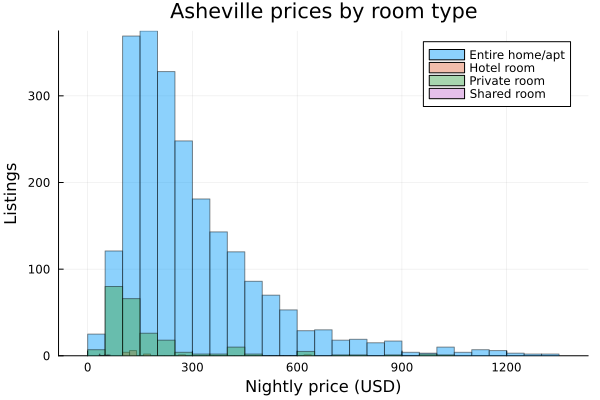

In [ ]:
if data_available
    room_types = sort(collect(skipmissing(unique(airbnb.room_type))))
    all_prices = Float64.(collect(skipmissing(airbnb.price_clean)))
    price_cap = isempty(all_prices) ? 1.0 : quantile(all_prices, 0.99)
    p_room = plot(xlabel="Nightly price (USD)", ylabel="Listings", title="Asheville prices by room type")
    for room in room_types
        room_mask = coalesce.(airbnb.room_type .== room, false)
        values = Float64.(collect(skipmissing(airbnb.price_clean[room_mask])))
        values = filter(p -> 0 <= p <= price_cap, values)
        isempty(values) || histogram!(p_room, values; bins=30, alpha=0.45, label=String(room))
    end
    p_room
else
    plot(title="Price distribution unavailable offline", legend=false)
end

### Discuss the Price Plot

- Which room type has the highest typical nightly price? Is that surprising?
- Compare spread as well as the center: where is host-side product differentiation strongest?
- The right tail reminds us that a platform hosts several submarkets, not one homogeneous good

## Reviews per Month and Price

- Reviews are an imperfect proxy for booking activity
- Price is an imperfect proxy for quality
- A scatter plot will not identify a demand curve
  - Expensive listings may also be larger, better located, or available less often
- Still, the joint distribution can reveal segmentation and unusual listings
- We again skip missing values explicitly

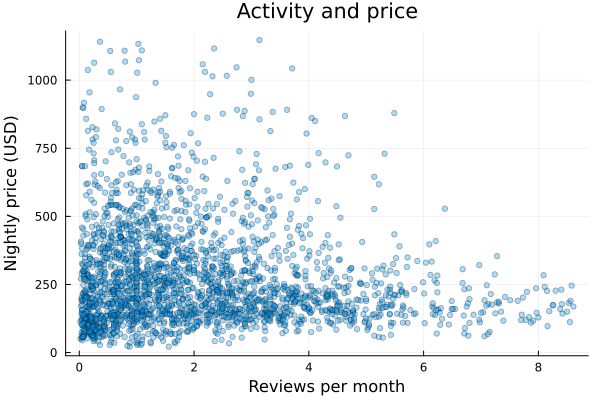

In [ ]:
if data_available
    review_values = Float64[]
    scatter_prices = Float64[]
    for row in eachrow(airbnb)
        if !ismissing(row.reviews_per_month) && !ismissing(row.price_clean)
            push!(review_values, Float64(row.reviews_per_month))
            push!(scatter_prices, Float64(row.price_clean))
        end
    end
    review_cap = isempty(review_values) ? 1.0 : quantile(review_values, 0.99)
    scatter_cap = isempty(scatter_prices) ? 1.0 : quantile(scatter_prices, 0.99)
    visible = (review_values .<= review_cap) .& (scatter_prices .<= scatter_cap) .& (scatter_prices .>= 0)
    scatter(review_values[visible], scatter_prices[visible]; alpha=0.35, markersize=3, legend=false,
        xlabel="Reviews per month", ylabel="Nightly price (USD)", title="Activity and price")
else
    plot(title="Review–price scatter unavailable offline", legend=false)
end

### Discuss the Scatter Plot

- Is there a clear relationship, or mostly a cloud?
- Which mechanisms could produce a negative association between price and reviews per month?
- Why would interpreting this picture causally be a mistake? Name at least two omitted variables

## When Reviews Keep a Market Alive

- A guest discovers a listing's true quality only after staying
- Guests pay expected quality; good hosts may reject that price and leave
- Average quality falls, bids fall, and more good hosts leave
- This **{term}`adverse selection`** changes who participates: the lemons mechanism (E&K §22.6)
- Could trade shrink even if guests value every listing above its host's cost?
- [The diagram below](#fig-lemons-unraveling) draws the spiral, and the circuit breaker that reputation adds

<a name="fig-lemons-unraveling" href="#fig-lemons-unraveling" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

Without reputation, guests pay every listing the market's average quality; hosts whose costs exceed that price leave, pulling the average down and repeating the spiral. Reputation prices each host on their own track record instead of the average, breaking the loop so good hosts keep earning above cost.

### A Tiny Market with Hidden Quality

- Draw fixed seller qualities $q_i$ uniformly from $[0,1]$; buyers value service at $q_i$, while sellers require $0.8q_i$
- Buyers pay mean remaining quality; sellers requiring more exit permanently
- Each seller serves one buyer per round; buyers are plentiful and risk neutral
- With **reputation**, buyers instead estimate each seller's quality from their mean past rating (E&K §22.9)
- Ratings are $q_i$ plus independent noise. Assume five platform-funded trial transactions establish each seller's initial record, then every sale adds a rating
- Mean ratings estimate quality; they are not exact Bayesian expectations. Trials require funding

In [ ]:
function quality_market(quality; reputation=false, noise=0.12, rounds=30, seed=2209)
    rng = MersenneTwister(seed)
    n_sellers = length(quality)
    active = trues(n_sellers)
    reservation = 0.8 .* quality
    counts = fill(5, n_sellers)
    rating_sum = 5 .* quality .+ noise .* vec(sum(randn(rng, n_sellers, 5); dims=2))
    high_quality = quality .>= 0.75
    history = DataFrame(round=Int[], share=Float64[], quality=Float64[], high_share=Float64[])
    for round in 0:rounds
        average_quality = any(active) ? mean(quality[active]) : NaN
        high_share = any(high_quality) ? mean(active[high_quality]) : NaN
        push!(history, (round, mean(active), average_quality, high_share))
        (round == rounds || !any(active)) && break
        prices = reputation ? clamp.(rating_sum ./ counts, 0, 1) : fill(average_quality, n_sellers)
        active .&= prices .>= reservation
        if reputation
            # Only completed transactions produce new ratings.
            rating_sum[active] .+= quality[active] .+ noise .* randn(rng, count(active))
            counts[active] .+= 1
        end
    end
    return history
end

seller_quality = rand(MersenneTwister(2206), 1000)
pooled_market = quality_market(seller_quality)
rated_market = quality_market(seller_quality; reputation=true)

Row,round,share,quality,high_share
,Int64,Float64,Float64,Float64
1,0,1.0,0.50354,1.0
2,1,0.884,0.546842,1.0
3,2,0.87,0.553308,1.0
4,3,0.867,0.55406,1.0
5,4,0.861,0.5566,1.0
6,5,0.856,0.558759,1.0
7,6,0.853,0.560376,1.0
8,7,0.85,0.561767,1.0
9,8,0.849,0.56237,1.0


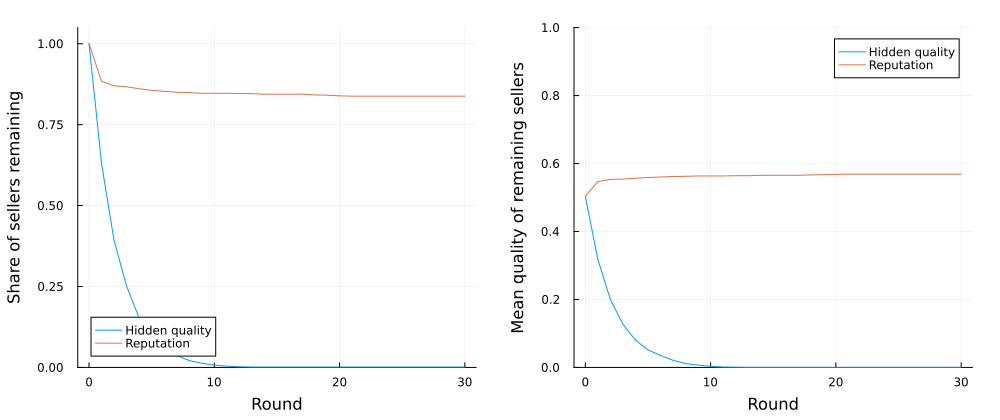

In [ ]:
p_share = plot(xlabel="Round", ylabel="Share of sellers remaining", ylim=(0, 1.05))
p_quality = plot(xlabel="Round", ylabel="Mean quality of remaining sellers", ylim=(0, 1))
for (result, label) in [(pooled_market, "Hidden quality"), (rated_market, "Reputation")]
    plot!(p_share, result.round, result.share; label)
    plot!(p_quality, result.round, result.quality; label)
end
plot(p_share, p_quality; layout=(1, 2), size=(1000, 420), margin=5 * Plots.mm)

### Information Changes Participation

- With hidden quality the market unravels almost completely: within 10 rounds fewer than 1% of sellers remain, and they are the worst ones
- Yet every guest values every listing above its host's cost. Trade that should happen does not
- Informative histories let high-quality sellers earn enough to stay. Check their retention below
- Ratings work here because quality is fixed, feedback is honest, and identities persist. Fake reviews or fresh identities can undermine that mechanism (E&K §22.9)

In [ ]:
(high_quality_retention_hidden=last(pooled_market.high_share),
 high_quality_retention_rated=last(rated_market.high_share))

(high_quality_retention_hidden = 0.0, high_quality_retention_rated = 1.0)

### Platforms Also Govern Behavior

- **{term}`Behavioral externalities <behavioral externality>`** arise from what participants do to others; network externalities arise from participation itself
- *Matchmakers* (ch. 9) describes four tools: Apple's App Store screened entry; eBay imposed transaction rules; Uber and BlaBlaCar used mutual ratings; OpenTable expelled repeated no-shows
- The book's social-network history: Friendster banned fake profiles but could not keep them out, and growth stalled; MySpace allowed anything, and advertisers (its money side) stayed away; Facebook required real identities from the start and enforced its rules
- Alibaba's TrustPass combined business authentication and feedback: trust infrastructure reduced the friction of trading with strangers (*Matchmakers*, ch. 4)
- More participants help only if people still want to transact with them

### Exercise 5: What Do Airbnb Reviews Tell Us?

- Our scatter plot uses `reviews_per_month`. Does that measure reputation, activity, or both?
- Propose data to distinguish these mechanisms and identify one selection bias
- Increase rating noise in the model. Predict and then compare high-quality retention
- Explain why a host with no reviews may struggle even when their listing is excellent

In [ ]:
# TODO: explain what reviews_per_month can and cannot measure
# TODO: propose additional fields and an Airbnb comparison
# TODO: vary noise, rerun, and interpret retention
nothing

## Who Supplies the Listings?

- The original story of Airbnb was peer-to-peer: one host, one spare room, one guest
- But platform growth can invite professional operators
- We will count listings by host and display the largest portfolios
- This is a same-side concentration question nested inside a cross-side marketplace

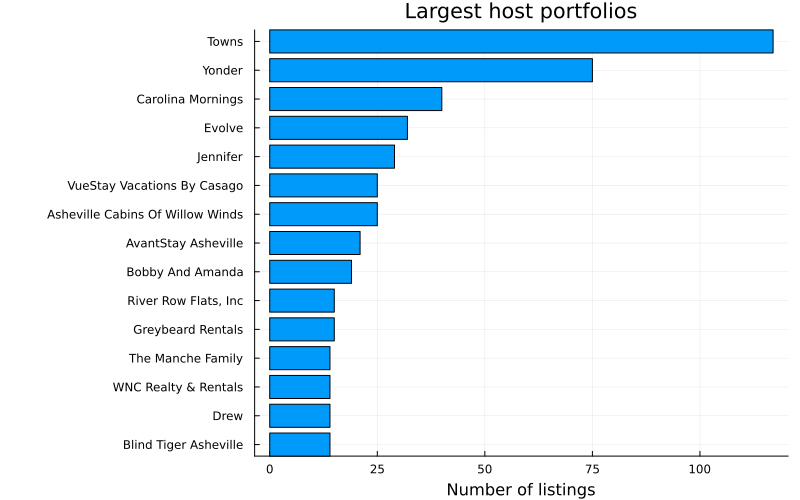

In [ ]:
if data_available
    host_rows = airbnb[.!ismissing.(airbnb.host_id), [:host_id, :host_name]]
    host_counts = combine(groupby(host_rows, [:host_id, :host_name]), nrow => :listing_count)
    sort!(host_counts, :listing_count, rev=true)
    top_hosts = first(host_counts, min(15, nrow(host_counts)))
    labels = [ismissing(name) ? "Host $(id)" : String(name) for (id, name) in zip(top_hosts.host_id, top_hosts.host_name)]
    n_hosts = length(labels)
    # permute=(:x, :y) draws horizontal bars while keeping one label per bar
    bar(reverse(top_hosts.listing_count); permute=(:x, :y), legend=false,
        xticks=(1:n_hosts, reverse(labels)), ylabel="Number of listings", xlabel="",
        title="Largest host portfolios", size=(800, 500), left_margin=10 * Plots.mm)
else
    plot(title="Host concentration unavailable offline", legend=false)
end

### Discuss Host Professionalization

- Do the largest portfolios look like occasional home sharing or a professional lodging business?
- How might professional hosts change same-side competition among hosts?
- How might they change cross-side value for guests through consistency, variety, or market power?
- Is Airbnb still peer-to-peer? The answer may depend on whether we describe the technology, the typical host, or the typical listing

### Exercise 6: Quantify Professionalization

- Compute the share of **listings** held by hosts with 10 or more listings
- Also compute the share of **hosts** with 10 or more listings
- Why are these two denominators telling different stories?
- What does your result imply for the platform's "peer-to-peer" framing?

In [ ]:
if data_available
    # TODO: use `host_counts.listing_count` from the previous analysis
    # TODO: compute listing share = listings held by 10+ hosts / all listings
    # TODO: compute host share = hosts with 10+ listings / all hosts
    nothing
else
    nothing
end

## The Platforms Unit in One Slide

- **[Platforms and Matchmakers](../week10/L10.01_platform_economics.ipynb):** Platforms create value by connecting sides through same-side / cross-side network effects
- **[Ignition](../week10/L10.02_ignition_and_tipping.ipynb):** They solve a {term}`chicken-and-egg problem`, fight toward {term}`critical mass`, and may experience {term}`tipping`
- **[Platform Pricing](../week11/L11.01_platform_pricing.ipynb):** They choose price structure as well as price level, often subsidizing one side
- **Today:** They sometimes replace prices with matching algorithms entirely
- **Market-clearing prices:** Prices can also support a matching that maximizes total valuation
- **Reputation:** Information about quality can keep good sellers participating; governance helps make that information credible
- **{term}`Multihoming <multihoming>`** can soften {term}`lock-in`, but it does not remove the platform's power to rank, recommend, price, or match
- Stable matching shows that the rules connecting agents determine who benefits—even when no money changes hands
- {term}`Matchmaking <matchmaker>` is the oldest business model—and maybe the newest: GPU and model marketplaces are two-sided markets for intelligence itself

## Next Time

- Platforms connect participants; next we build the participants themselves
- Weeks 12–13 turn to **AI agents**: {term}`LLMs <large language model, LLM>` that perceive, decide, call tools, and talk to each other
- Many of those agents will end up transacting on exactly the kind of platforms we just studied